In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/raw/city_day.csv', parse_dates=['Date'])

# Resume ku vendiya columns mattum
cols = ['City', 'Date', 'PM2.5', 'PM10', 'NO2', 'CO', 'AQI', 'AQI_Bucket']
df = df[cols]

print(df.shape)
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDate range:", df['Date'].min(), "to", df['Date'].max())
print("Cities:", df['City'].nunique())

(29531, 8)
City                     str
Date          datetime64[us]
PM2.5                float64
PM10                 float64
NO2                  float64
CO                   float64
AQI                  float64
AQI_Bucket               str
dtype: object

Missing values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO2            3585
CO             2059
AQI            4681
AQI_Bucket     4681
dtype: int64

Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Cities: 26


AQI_Bucket
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64
              PM2.5          PM10           NO2            CO
count  24933.000000  18391.000000  25946.000000  27472.000000
mean      67.450578    118.127103     28.560659      2.248598
std       64.661449     90.605110     24.474746      6.962884
min        0.040000      0.010000      0.010000      0.000000
25%       28.820000     56.255000     11.750000      0.510000
50%       48.570000     95.680000     21.690000      0.890000
75%       80.590000    149.745000     37.620000      1.450000
max      949.990000   1000.000000    362.210000    175.810000


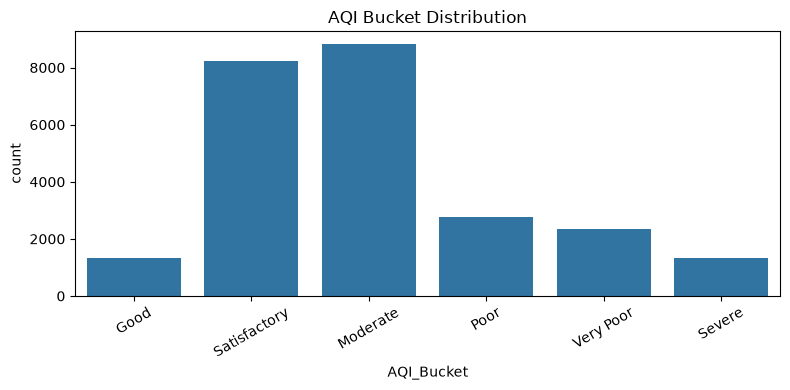

In [2]:
# Class distribution
print(df['AQI_Bucket'].value_counts())

# Summary stats of pollutants
print(df[['PM2.5', 'PM10', 'NO2', 'CO']].describe())

# Plot class distribution
plt.figure(figsize=(8, 4))
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
sns.countplot(data=df, x='AQI_Bucket', order=order)
plt.title('AQI Bucket Distribution')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

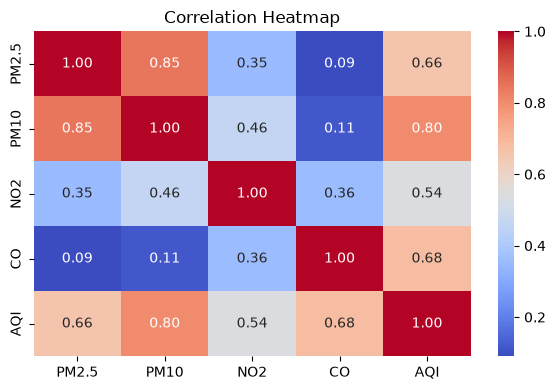

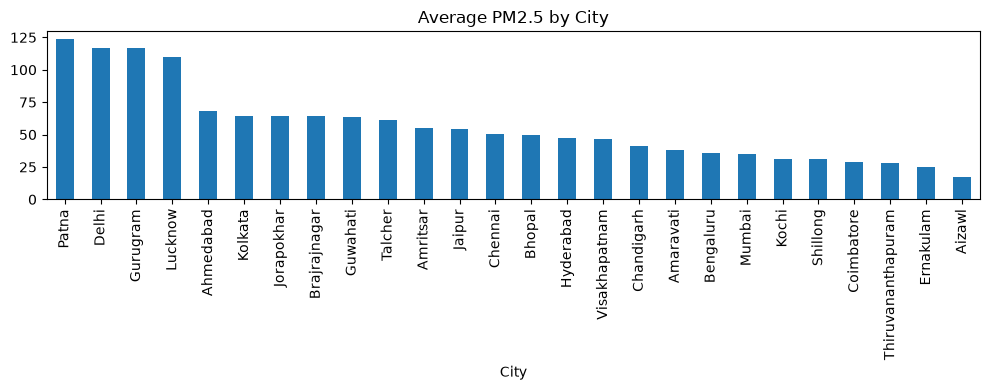

In [3]:
# Correlation between pollutants and AQI
plt.figure(figsize=(6, 4))
sns.heatmap(df[['PM2.5', 'PM10', 'NO2', 'CO', 'AQI']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# Average PM2.5 by city
plt.figure(figsize=(10, 4))
df.groupby('City')['PM2.5'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average PM2.5 by City')
plt.tight_layout()
plt.show()